# Inspecting the Lichess Puzzle Dataset

This notebook inspects the original compressed CSV without changing it. Run the cells in order using the project's `.venv` kernel.

We will preview records, check basic data quality, and examine ratings, solution lengths, and themes. This is a **data audit**, not chess-legality validation. No puzzles are removed or sampled here.

Historical outputs from the completed October 13 data preparation are retained. Only repository-path discovery was adapted for this notebook folder. Rerun inspection if needed; rerun full validation only if the source data or validation method changes. The byte-exact original notebook is preserved in `archive/pre_first_move_code.zip`.

## 1. Import libraries and locate the dataset
The path works when the notebook starts in either the repository root or the `code` folder.

In [1]:
# Import the tools used for tables, counting, charts, and documentation.
from pathlib import Path
from collections import Counter
from datetime import datetime, timezone
import hashlib
import json
import math

import pandas as pd
import matplotlib.pyplot as plt

# Find the repository from the current working directory.
project_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data/lichess_db_puzzle.csv.zst").is_file())

csv_path = project_root / "data" / "lichess_db_puzzle.csv.zst"
assert csv_path.is_file(), f"Dataset not found: {csv_path}"
print("Dataset:", csv_path)
print(f"Compressed size: {csv_path.stat().st_size / 1_000_000:.1f} MB")

Dataset: e:\DA_401\LLM_Chess_Comparison\data\lichess_db_puzzle.csv.zst
Compressed size: 307.2 MB


## 2. Preview records and columns
Read only five rows. Keep fields as strings to preserve puzzle IDs and inspect the original values.

In [2]:
# Read a tiny preview directly from the compressed file.
preview = pd.read_csv(csv_path, compression="zstd", nrows=5,
                      dtype=str, keep_default_na=False)
print("Columns:", preview.columns.tolist())
display(preview)

Columns: ['PuzzleId', 'FEN', 'Moves', 'Rating', 'RatingDeviation', 'Popularity', 'NbPlays', 'Themes', 'GameUrl', 'OpeningTags', 'DailyDate']


,PuzzleId,FEN,Moves,Rating,RatingDeviation,Popularity,NbPlays,Themes,GameUrl,OpeningTags,DailyDate
0,00008,r6k/pp2r2p/4Rp1Q/3p4/8/1N1P2R1/PqP2bPP/7K b - ...,f2g3 e6e7 b2b1 b3c1 b1c1 h6c1,1811,76,95,10282,crushing hangingPiece long middlegame,https://lichess.org/787zsVup/black#48,,
1,0000D,5rk1/1p3ppp/pq3b2/8/8/1P1Q1N2/P4PPP/3R2K1 w - ...,d3d6 f8d8 d6d8 f6d8,1529,74,96,37506,advantage endgame short,https://lichess.org/F8M8OS71#53,,
2,0000H,r4rk1/pp3ppp/8/2bqp2b/3N4/P2Bn2P/1PPN1P2/R1BQ1...,d1h5 d5g2,1554,223,100,11,mate mateIn1 middlegame oneMove,https://lichess.org/EwHRkfas#29,French_Defense French_Defense_Tarrasch_Variation,
3,0008Q,8/4R3/1p2P3/p4r2/P6p/1P3Pk1/4K3/8 w - - 1 64,e7f7 f5e5 e2f1 e5e6,1383,81,92,771,advantage endgame rookEndgame short,https://lichess.org/MQSyb3KW#127,,
4,0009B,r2qr1k1/b1p2ppp/pp4n1/P1P1p3/4P1n1/B2P2Pb/3NBP...,b6c5 e2g4 h3g4 d1g4,1084,74,88,611,advantage middlegame short,https://lichess.org/4MWQCxQ6/black#32,Kings_Pawn_Game Kings_Pawn_Game_Leonardis_Vari...,


## 3. Scan the dataset in chunks

Read 100,000 rows at a time rather than loading the entire CSV. Collect missing-value counts, duplicate IDs, numeric errors, ratings, themes, and move lengths.

Exact duplicate detection keeps a set of puzzle IDs in memory. Other summaries use compact frequency tables. Blank optional fields are counted but do not cause records to be removed.

In [3]:
# Initialize counters before each full scan so rerunning this cell resets results.
row_count = 0
missing_counts = Counter()
invalid_numeric = Counter()
rating_counts = Counter()
solver_move_counts = Counter()
theme_counts = Counter()
seen_ids = set()
duplicate_ids = 0
short_sequences = 0
numeric_columns = ["Rating", "RatingDeviation", "NbPlays", "Popularity"]

# Process one chunk at a time and retain summaries rather than whole tables.
chunks = pd.read_csv(csv_path, compression="zstd", chunksize=100_000,
                     dtype=str, keep_default_na=False)
for chunk in chunks:
    row_count += len(chunk)

    # Count blank fields and nonblank values that cannot be read as numbers.
    for column in chunk.columns:
        missing_counts[column] += int(chunk[column].str.strip().eq("").sum())
    for column in numeric_columns:
        numbers = pd.to_numeric(chunk[column], errors="coerce")
        invalid_numeric[column] += int((numbers.isna() & chunk[column].str.strip().ne("")).sum())
        if column == "Rating":
            rating_counts.update(numbers.dropna().value_counts().to_dict())

    # Count repeated nonblank puzzle IDs across all chunks.
    for puzzle_id in chunk["PuzzleId"]:
        if puzzle_id.strip():
            if puzzle_id in seen_ids:
                duplicate_ids += 1
            seen_ids.add(puzzle_id)

    # The first listed move belongs to the opponent; solver moves are indices 1, 3, 5...
    for moves in chunk["Moves"]:
        total_plies = len(moves.split())
        if total_plies < 2:
            short_sequences += 1
        else:
            solver_move_counts[total_plies // 2] += 1

    # Count each theme once per puzzle because labels are multilabel features.
    for themes in chunk["Themes"]:
        theme_counts.update(set(themes.split()))

    if row_count % 1_000_000 == 0:
        print(f"Inspected {row_count:,} rows")

print(f"Finished: {row_count:,} rows")

Inspected 1,000,000 rows
Inspected 2,000,000 rows
Inspected 3,000,000 rows
Inspected 4,000,000 rows
Inspected 5,000,000 rows
Inspected 6,000,000 rows
Finished: 6,157,341 rows


## 4. Review basic data quality
Duplicates refer to extra rows after the first occurrence of each ID. Numeric checks detect parsing errors, not every possible out-of-range value.

In [4]:
# Display the structural checks and missing values for every column.
print(f"Unique nonblank IDs: {len(seen_ids):,}")
print(f"Duplicate ID rows: {duplicate_ids:,}")
print(f"Sequences with fewer than two moves: {short_sequences:,}")
display(pd.Series(missing_counts, name="Blank values").to_frame())
display(pd.Series(invalid_numeric, name="Invalid numeric values").to_frame())

Unique nonblank IDs: 6,157,341
Duplicate ID rows: 0
Sequences with fewer than two moves: 0


,Blank values
PuzzleId,0
FEN,0
Moves,0
Rating,0
RatingDeviation,0
Popularity,0
NbPlays,0
Themes,0
GameUrl,0
OpeningTags,4932426


,Invalid numeric values
Rating,0
RatingDeviation,0
NbPlays,0
Popularity,0


## 5. Examine human puzzle ratings

Build a frequency table and find observed-value percentiles using cumulative counts. These use the nearest-rank definition, which may differ slightly from interpolated percentiles.

The 33rd and 67th percentiles are candidate boundaries for three difficulty groups, **not finalized sampling rules**. Revisit them after chess validation and any quality filters.

Minimum rating: 399
Maximum rating: 3323
Mean rating: 1468.9


,Rating
25th,1041.0
33rd,1157.0
50th,1413.0
67th,1700.0
75th,1870.0


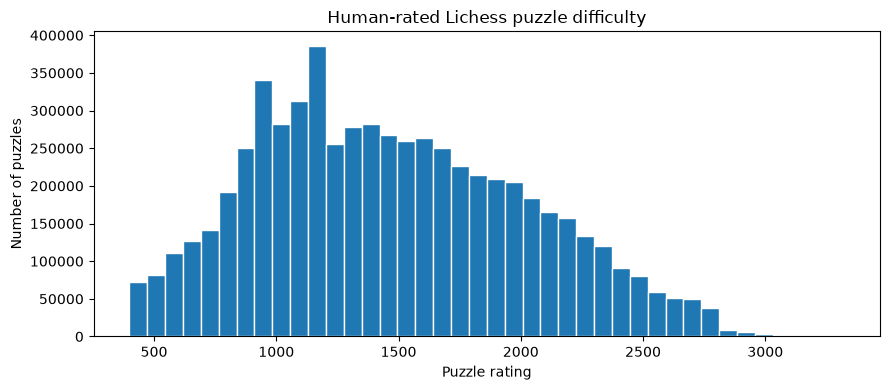

In [5]:
# Summarize ratings without expanding the frequency table into millions of rows.
ratings = pd.Series(rating_counts, name="Puzzle count").sort_index()
cumulative_counts = ratings.cumsum()
valid_rating_count = int(ratings.sum())
assert valid_rating_count > 0, "No valid ratings were found."

# Calculate observed rating thresholds for selected percentiles.
percentiles = {}
for label, fraction in [("25th", 0.25), ("33rd", 1/3), ("50th", 0.5),
                        ("67th", 2/3), ("75th", 0.75)]:
    rank = math.ceil(valid_rating_count * fraction)
    percentiles[label] = float(cumulative_counts[cumulative_counts >= rank].index[0])

print("Minimum rating:", ratings.index.min())
print("Maximum rating:", ratings.index.max())
print("Mean rating:", round((ratings.index.to_numpy() * ratings.to_numpy()).sum() / valid_rating_count, 1))
display(pd.Series(percentiles, name="Rating").to_frame())

# Plot a histogram weighted by how many puzzles have each rating.
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(ratings.index, bins=40, weights=ratings.values, edgecolor="white")
ax.set(title="Human-rated Lichess puzzle difficulty", xlabel="Puzzle rating", ylabel="Number of puzzles")
plt.tight_layout()
plt.show()

## 6. Examine required solver moves
A ply is one move by either side. Required solver moves exclude the initiating opponent move and subsequent opponent replies. Counts assume the documented Lichess format; legality is not checked here.

,Puzzle count
1,915589
2,3116759
3,1617605
4,361432
5,97707
6,30889
7,10848
8,4067
9,1461
10,619


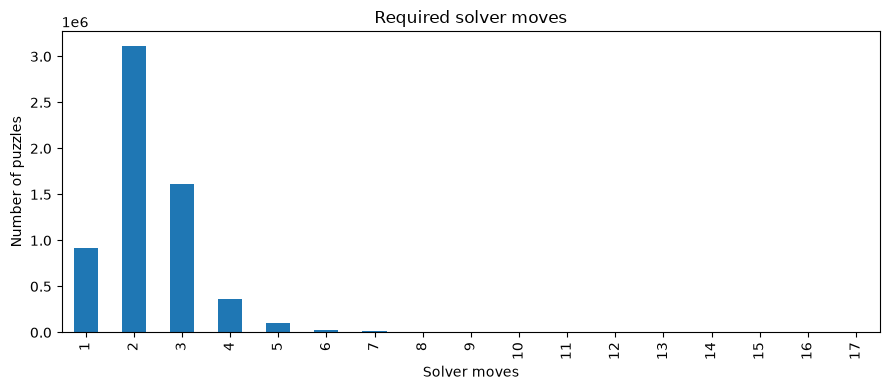

In [6]:
# Display and plot how many model moves each official solution requires.
solution_lengths = pd.Series(solver_move_counts, name="Puzzle count").sort_index()
display(solution_lengths.to_frame())

fig, ax = plt.subplots(figsize=(9, 4))
solution_lengths.plot.bar(ax=ax)
ax.set(title="Required solver moves", xlabel="Solver moves", ylabel="Number of puzzles")
plt.tight_layout()
plt.show()

## 7. Examine common themes
Theme counts overlap because one puzzle can have several labels. Some labels describe phase or length rather than a tactical motif.

,Puzzle count
endgame,3090839
short,3090809
middlegame,2773603
crushing,2361455
mate,1957166
advantage,1771464
long,1599523
oneMove,910793
mateIn1,908244
master,841076


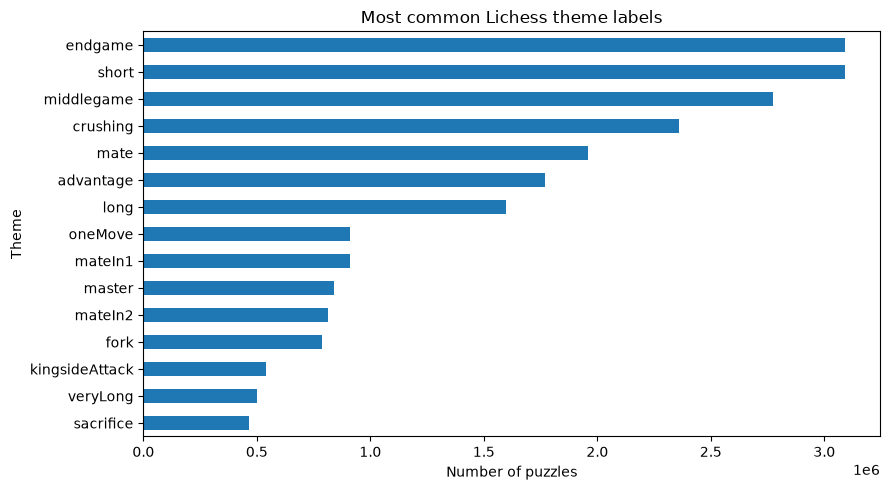

In [7]:
# Show the fifteen most frequent labels; these are not yet chosen regression features.
common_themes = pd.Series(dict(theme_counts.most_common(15)), name="Puzzle count")
display(common_themes.to_frame())

fig, ax = plt.subplots(figsize=(9, 5))
common_themes.sort_values().plot.barh(ax=ax)
ax.set(title="Most common Lichess theme labels", xlabel="Number of puzzles", ylabel="Theme")
plt.tight_layout()
plt.show()

## 8. Save an audit report
Calculate a checksum to identify this exact source file. Save a separate notebook report so the earlier script audit is preserved. The inspection timestamp is not the download date.

In [8]:
# Hash the compressed file in small blocks without changing it.
checksum = hashlib.sha256()
with csv_path.open("rb") as source:
    for block in iter(lambda: source.read(1024 * 1024), b""):
        checksum.update(block)

# Save only observed summaries, leaving the raw file unchanged.
report = {
    "source": str(csv_path.resolve()),
    "source_url": "https://database.lichess.org/#puzzles",
    "download_date": None,
    "inspection_timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "size_bytes": csv_path.stat().st_size,
    "sha256": checksum.hexdigest(),
    "rows": row_count,
    "columns": preview.columns.tolist(),
    "blank_values_by_column": dict(missing_counts),
    "duplicate_id_rows_after_first": duplicate_ids,
    "invalid_nonblank_numeric_values": dict(invalid_numeric),
    "sequences_with_fewer_than_two_plies": short_sequences,
    "rating_percentiles_nearest_rank": percentiles,
    "required_solver_moves": dict(sorted(solver_move_counts.items())),
    "theme_counts": dict(theme_counts.most_common()),
    "notes": ["No records removed; no FEN or move-legality validation performed.",
              "Download date is unknown until supplied by the researcher."]
}
report_path = project_root / "data" / "inspection" / "notebook_audit.json"
report_path.parent.mkdir(parents=True, exist_ok=True)
report_path.write_text(json.dumps(report, indent=2), encoding="utf-8")
print("Saved report:", report_path)
print("Source SHA-256:", report["sha256"])

Saved report: e:\DA_401\LLM_Chess_Comparison\data\inspection\notebook_audit.json
Source SHA-256: 76335bfa7d7c4a7f93c1366d81549e53951ebb79dd43d34904cab8f22d962f8d


## Next research step

Validate FEN strings and official move sequences, applying the initiating move before computing board features. Then decide quality filters and rating strata, and draw a reproducible preliminary sample.

Before sharing results, use **Restart Kernel ? Run All** to verify the notebook runs in order.